# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [58]:
# run this first if you dont have them installed in your env
!pip install pandas numpy matplotlib scipy

Defaulting to user installation because normal site-packages is not writeable


In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("../data/cars.csv")
print(df.shape)
df.head()

(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [135]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()


#df.columns.tolist() #I can see all the columns in my dataset
len(df) #get all the rows in my dataset

print("\nDuplicated values in the Make column:")
if df["Make"].nunique() == df["Make"].notna().sum(): #They should be the same, if not, there are duplicate values
    print("There are no duplicate values in the Make column")
else:
    print("There are duplicate values in the Make column")
#However because its cars, there are some duplicates, so I will not drop them

#COUNT THINGS TWICE
print("\nDuplicated rows:")
display(df.duplicated().sum()) #Returns the number of duplicated rows. At first, duplicated() returns a 
# True/False Series with one entry per row. A row is marked True if every column value matches a 
# row that appeared earlier in the DataFrame. The first occurrence is marked False, 
# and only the later copies are marked True. And the sum() adds up all the True values. 720 are duplicated


#MISSING VALUES HAVE A REASON. WHO IS MISSING?
print("\nMissing values:")
display(df.isna().sum())  #Theres 3 columns with NaN values, 3 in Engine Fuel Type, 69 in Engine HP and 30 in Engine Cylinders.
#print(df[df.isna().any(axis=1)]) #I can see the rows with missing values

print("\nMost expensive cars:")
display(df.nlargest(10, "MSRP")[["Make", "Model", "Year", "MSRP"]])

#2000 is the most common price by a long shot, it has to be either a placeholder or a mistake, since 
# the next value after 2000 increases significantly
print("\nMost common prices:")
top_msrps = df["MSRP"].value_counts().head(10).index
display(
    df[df["MSRP"].isin(top_msrps)][["Make", "Model", "Year", "MSRP"]]
)

msrp_2000 = df[df["MSRP"] == 2000]
display(msrp_2000)


Duplicated values in the Make column:
There are duplicate values in the Make column

Duplicated rows:


np.int64(720)


Missing values:


Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64


Most expensive cars:


,Make,Model,Year,MSRP
11362,Bugatti,Veyron 16.4,2008,2065902
11364,Bugatti,Veyron 16.4,2009,1705769
8486,Lamborghini,Reventon,2008,1500000
11363,Bugatti,Veyron 16.4,2008,1500000
6351,Maybach,Landaulet,2012,1382750
6350,Maybach,Landaulet,2011,1380000
4024,Ferrari,Enzo,2003,643330
1622,Lamborghini,Aventador,2014,548800
1626,Lamborghini,Aventador,2015,548800
1629,Lamborghini,Aventador,2016,535500



Most common prices:


,Make,Model,Year,MSRP
17,Audi,100,1992,2000
18,Audi,100,1992,2000
19,Audi,100,1992,2000
20,Audi,100,1992,2000
21,Audi,100,1992,2000
...,...,...,...,...
11794,Subaru,XT,1991,2000
11795,Subaru,XV Crosstrek,2013,21995
11798,Subaru,XV Crosstrek,2014,25995
11802,Subaru,XV Crosstrek,2014,21995


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
17,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
18,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
19,Audi,100,1992,regular unleaded,172.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,Wagon,20,16,3105,2000
20,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,front wheel drive,4.0,Midsize,Sedan,24,17,3105,2000
21,Audi,100,1992,regular unleaded,172.0,6.0,MANUAL,all wheel drive,4.0,Midsize,Sedan,21,16,3105,2000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11481,Suzuki,X-90,1998,regular unleaded,95.0,4.0,MANUAL,four wheel drive,2.0,Compact,2dr SUV,26,22,481,2000
11482,Suzuki,X-90,1998,regular unleaded,95.0,4.0,MANUAL,rear wheel drive,2.0,Compact,2dr SUV,26,22,481,2000
11792,Subaru,XT,1991,regular unleaded,97.0,4.0,MANUAL,front wheel drive,2.0,Compact,Coupe,29,22,640,2000
11793,Subaru,XT,1991,regular unleaded,145.0,6.0,AUTOMATIC,front wheel drive,2.0,Compact,Coupe,26,18,640,2000


**Cleaning log:** fill in one row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | Duplicated Rows| df.duplicated().sum() | 720 | I removed them | Beacuse if theres another row that covers the exact model and the same information theres no need to keep it|
| 2 | A 2000 value repeated constantly in MSRP| df["MSRP"].value_counts().head(10).index | 1036 | I replaced them with NaN| Because theres way too many models from several brands with that exact price, including models in other rows are expensive, that integer has to be a placeholder |
| 3 | Engine HP| df.isna().sum()| 69 | Nothing modified | There could be models that dont count that information and still be on sale |


In [133]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
clean = df.copy()

# Drop duplicates
clean = clean.drop_duplicates()

#Remove the placeholder price since its in more than 100 rows
clean["MSRP"] = clean["MSRP"].replace(2000, np.nan)


clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names

print(clean.shape)
clean.head()

(11194, 15)


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135.0
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650.0
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350.0
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450.0
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500.0


In [134]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11194, 15)
engine_fuel_type      3
engine_hp            69
engine_cylinders     30
number_of_doors       6
msrp                747
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

44788.66689001627
31870.0
24.45 % of the cars cost more than the mean


/var/folders/ds/ykqm05x91vl1bnhx9bcryrp00000gn/T/ipykernel_20741/2353378432.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


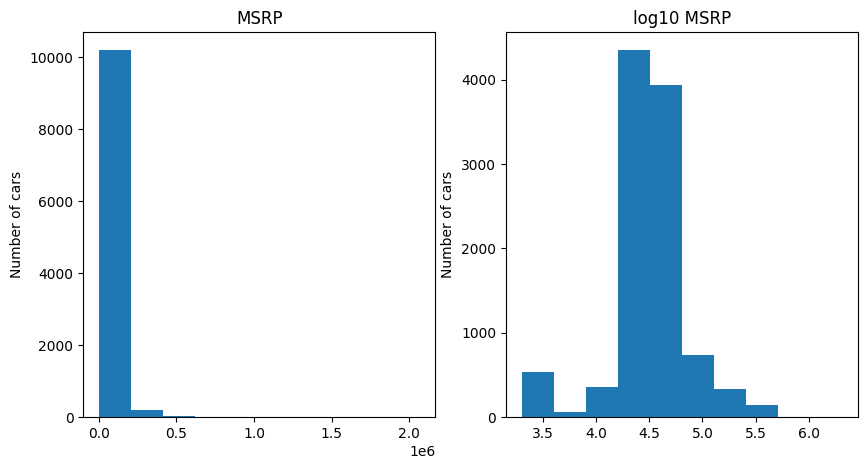

In [81]:
# a) mean and median
mean = clean["msrp"].sum()/ clean["msrp"].count()
print(mean)

median = clean["msrp"].median()
print(median)

#or get the median like this>
#prices = clean["MSRP"].dropna().sort_values().reset_index(drop=True)
#n = len(prices)
#if n % 2 == 1:
    #median = prices[n // 2]
#else:
    #median = (prices[n // 2 - 1] + prices[n // 2]) / 2

# b) two histograms side by side (plt.subplots(1, 2))
#plt.subplots(rows, cols) creates a figure (the canvas) and a grid of axes.
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

axs[0].hist(clean['msrp'])
axs[0].set_title('MSRP')
axs[0].set_ylabel("Number of cars")

axs[1].hist(np.log10(clean['msrp']))
axs[1].set_ylabel("Number of cars")
axs[1].set_title('log10 MSRP')

fig.show()



# c) share of cars above the mean
share_above_mean= (clean['msrp'] > mean).sum() /clean["msrp"].count() #Im not counting the NaN values, placeholder 2000 is not included
print(f'{share_above_mean *100:.2f} % of the cars cost more than the mean')

**Answer:**

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [95]:
# a) mean and std of highway_mpg by vehicle_size, 2017 only
print("\n2017 cars:")

cars_2017 = clean[clean["year"] == 2017]
print(len(cars_2017))   # how many 2017 cars
print(cars_2017["year"].unique()) #just to check
display(
    cars_2017[["make", "model", "highway_mpg", "vehicle_size"]]
)
mean_std_2017= cars_2017.groupby("vehicle_size")["highway_mpg"].agg(["mean", "std"])
display(mean_std_2017)


# b) z = (value - class mean) / class std
honda_civic_z_score = (42 - 31.994197) / 10.784983
volvo_z_score = (34  - 22.991453) / 3.491184
print(f"Honda Civic z-score: {honda_civic_z_score:.2f}")
print(f"Volvo S90 z-score: {volvo_z_score:.2f}")

#c)


2017 cars:
1624
[2017]


,make,model,highway_mpg,vehicle_size
32,FIAT,124 Spider,35,Compact
33,FIAT,124 Spider,35,Compact
34,FIAT,124 Spider,35,Compact
50,BMW,2 Series,31,Compact
51,BMW,2 Series,32,Compact
...,...,...,...,...
11876,GMC,Yukon,23,Large
11877,GMC,Yukon,22,Large
11878,GMC,Yukon,22,Large
11879,GMC,Yukon,22,Large


,mean,std
vehicle_size,,
Compact,31.994197,10.784983
Large,22.991453,3.491184
Midsize,29.918623,13.948504


Honda Civic z-score: 0.93
Volvo S90 z-score: 3.15


**Answer:**
The Z-score of 3.15 means the Volvo it’s more than 3 standard deviations above its category mean. The Honda Civic, at 0.93 is the one that’s not even 1 std from the mean. Therefore the Volvo is considerably more efficient compared to its class.

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

Median MSRP of 2017 cars: $36,737.50
95% interval: $35,940.00 to $37,682.56


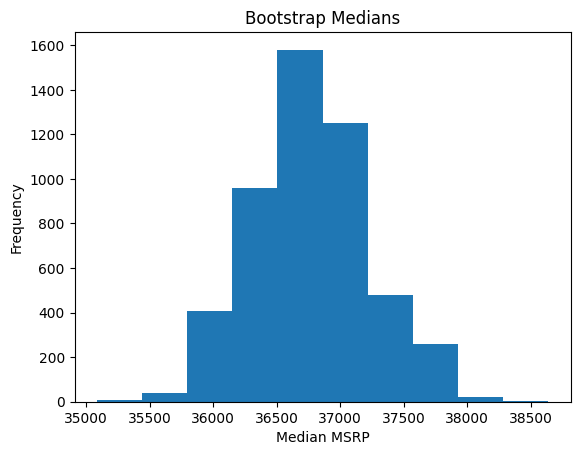

In [ ]:
rng = np.random.default_rng(42)

def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    # hint: rng.choice(values, size=len(values), replace=True)
    values = np.asarray(values)
    medians = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        medians[i] = np.median(sample)

    return medians

# a, b)
median_2017= cars_2017["msrp"].median()
print(f"Median MSRP of 2017 cars: ${median_2017:,.2f}")

boot_medians = bootstrap_median(cars_2017["msrp"])
lo, hi = np.percentile(boot_medians, [2.5, 97.5])
print(f"95% interval: ${lo:,.2f} to ${hi:,.2f}")

# c)
#After removing the bottom 2.5 and top 2.5 percent of the data, the interval is narrower. This is 
# because the median is less affected by extreme values, so the bootstrap distribution is more concentrated.

plt.hist(boot_medians)
plt.title("Bootstrap Medians")
plt.xlabel("Median MSRP")
plt.ylabel("Frequency")
plt.show()


**Answer:**
After removing the bottom 2.5 and top 2.5 percent of the data, the interval is narrower. This is 
because the median is less affected by extreme values, so the bootstrap distribution is more concentrated.


---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

517


make
Chevrolet        60
Nissan           60
Toyota           58
Volkswagen       42
Ford             33
Honda            27
Audi             25
Mitsubishi       22
Subaru           21
Kia              20
FIAT             19
Hyundai          17
Porsche          16
BMW              13
Mazda            13
Mercedes-Benz    12
Buick            10
Cadillac          9
GMC               9
Lincoln           8
Land Rover        8
Acura             7
Dodge             4
Infiniti          2
Lexus             1
Lotus             1
Name: count, dtype: int64

Mean highway MPG for Chevrolet compacts: 32.53
Mean highway MPG for Nissan compacts: 27.05
Mean highway MPG for Toyota compacts: 32.14
Mean highway MPG for Volkswagen compacts: 30.90
Mean highway MPG for Ford compacts: 34.52
Mean highway MPG for Honda compacts: 36.89


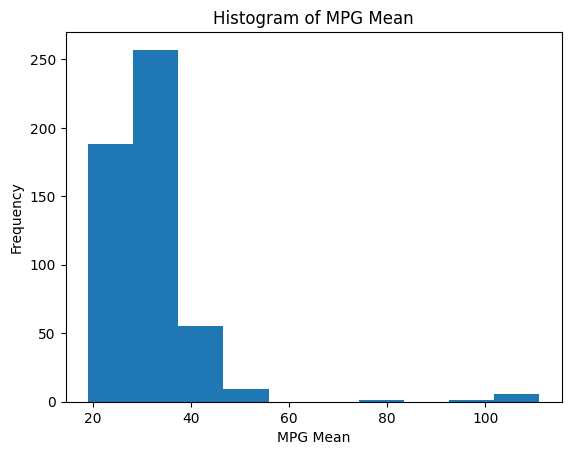

t = 4.20, p = 1.54e-05
t = 3.10, p = 1.31e-03


In [125]:
# b) sample: 2017 compact cars (MPG you trust); n, mean, histogram

compact_2017 = cars_2017[cars_2017["vehicle_size"] == "Compact"]
print(len(compact_2017))
brands= compact_2017["make"].value_counts()
display(brands)
mpg_compacts= compact_2017["highway_mpg"]

#cheking the mean of the top 5 most common brands
mean_chevrolet= compact_2017[compact_2017["make"] == "Chevrolet"]["highway_mpg"].mean()
print(f"Mean highway MPG for Chevrolet compacts: {mean_chevrolet:.2f}")
mean_nissan= compact_2017[compact_2017["make"] == "Nissan"]["highway_mpg"].mean()
print(f"Mean highway MPG for Nissan compacts: {mean_nissan:.2f}")
mean_toyota= compact_2017[compact_2017["make"] == "Toyota"]["highway_mpg"].mean()
print(f"Mean highway MPG for Toyota compacts: {mean_toyota:.2f}")
mean_volkswagen= compact_2017[compact_2017["make"] == "Volkswagen"]["highway_mpg"].mean()
print(f"Mean highway MPG for Volkswagen compacts: {mean_volkswagen:.2f}")
mean_ford= compact_2017[compact_2017["make"] == "Ford"]["highway_mpg"].mean()
print(f"Mean highway MPG for Ford compacts: {mean_ford:.2f}")
mean_honda= compact_2017[compact_2017["make"] == "Honda"]["highway_mpg"].mean()
print(f"Mean highway MPG for Honda compacts: {mean_honda:.2f}")

plt.hist(mpg_compacts)
plt.title("Histogram of MPG Mean")
plt.xlabel("MPG Mean")
plt.ylabel("Frequency")
plt.show()


# c) one-sample t-test vs 30

t_stat, p_value = stats.ttest_1samp(mpg_compacts, popmean=30, alternative="greater")
print(f"t = {t_stat:.2f}, p = {p_value:.2e}")


# d) rows per make+model, then one row per model and retest
model_mpg = compact_2017.groupby(['make', 'model'])['highway_mpg'].mean()
I_t_stat , I_p_value= stats.ttest_1samp(model_mpg, 30, alternative='greater')
print(f"t = {I_t_stat:.2f}, p = {I_p_value:.2e}")


**Answer:** 
For the null Hypothesis of Ho, we assume the true mean highway MPG of 2017 compact cars is 30. Fot Ha the true mean highway MPG of 2017 compact cars is greater than 30. This is a one-sided claim because it just says the mean is higher than 30. After the computations we can see how in both cases the p value is way less than 0.05, therefore we reject the null hypothesis, so marketing’s claim is supported by this test.

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

Median MSRP for automatic cars: $33,620.00
Median MSRP for manual cars: $21,875.00


year
2016    1627
2015    1564
2017    1320
2014     371
2007     264
2009     263
2012     249
2008     225
2010     211
2011     210
2013     205
2004     165
2005     159
2006     154
2003     152
2002     144
2001     100
1997      60
1995      59
1999      55
2000      54
1996      54
1998      51
1991      47
1993      44
1994      42
1990      40
1992      39
Name: count, dtype: int64

year
2015    330
2016    282
2017    201
1993    114
2014    110
1997    104
1998     94
2009     92
1992     88
2008     88
1994     87
2012     81
2013     80
2003     80
2011     70
2001     68
2010     68
2007     67
2004     63
1996     61
1995     58
2002     58
1999     57
2000     56
1991     54
2005     47
2006     38
1990     37
Name: count, dtype: int64

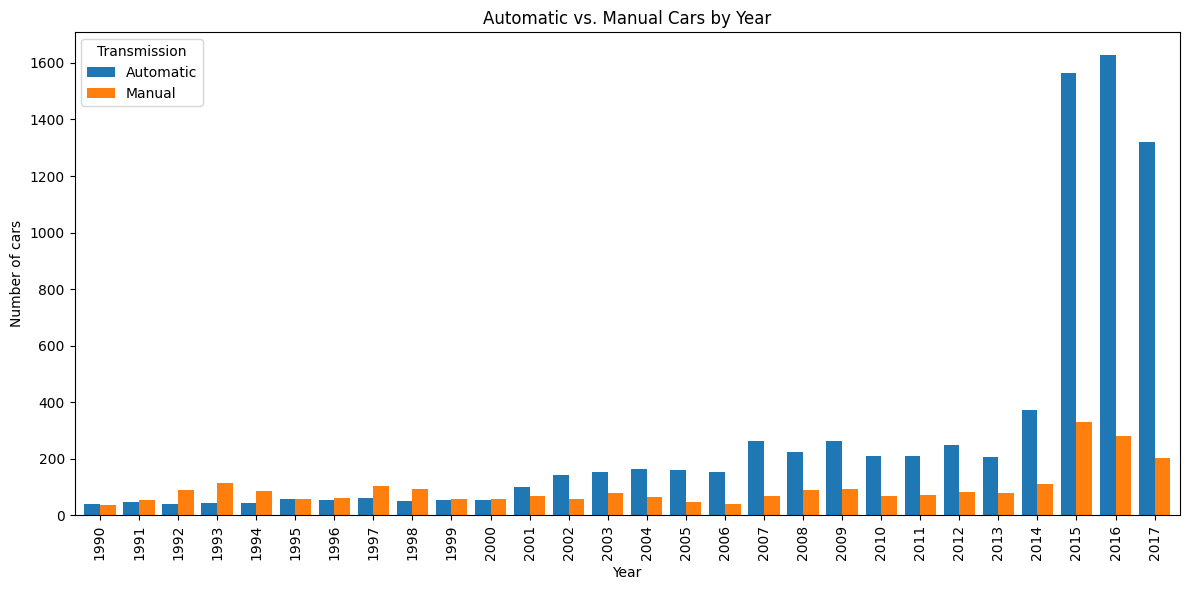

Overall median MSRP, 2015-2017:
transmission_type
AUTOMATED_MANUAL    $41,150.00
AUTOMATIC           $37,065.00
DIRECT_DRIVE        $35,595.00
MANUAL              $26,905.00
Name: msrp, dtype: object

Median MSRP by vehicle size, 2015-2017:


transmission_type,AUTOMATED_MANUAL,AUTOMATIC,DIRECT_DRIVE,MANUAL
vehicle_size,,,,
Compact,"$36,098","$25,995","$33,450","$25,860"
Large,"$105,850","$44,400","$77,250","$38,395"
Midsize,"$49,500","$37,980","$27,822","$26,920"



Compacts 2015-2017: n_auto=1119, n_manual=589
Mann-Whitney U = 317,261.0, p-value = 0.2048


In [131]:
# a) compare median MSRP by transmission type
median_automatic= clean[clean["transmission_type"]== "AUTOMATIC"]["msrp"].median()
median_manual= clean[clean["transmission_type"]== "MANUAL"]["msrp"].median()
print(f"Median MSRP for automatic cars: ${median_automatic:,.2f}")
print(f"Median MSRP for manual cars: ${median_manual:,.2f}")


# b) compare year by transmission type
years_automatic= clean[clean["transmission_type"] == "AUTOMATIC"]["year"].value_counts()
years_manual= clean[clean["transmission_type"] == "MANUAL"]["year"].value_counts()
display(years_automatic)
display(years_manual)


compare = pd.DataFrame({
    "Automatic": years_automatic,
    "Manual": years_manual
}).fillna(0).sort_index()

ax = compare.plot(kind="bar", figsize=(12, 6), width=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("Number of cars")
ax.set_title("Automatic vs. Manual Cars by Year")
ax.legend(title="Transmission")
plt.tight_layout()
plt.show()



# c) compare 2015-2017 medians overall and within each vehicle_size
# For 2015-17 compacts, test automatic vs manual prices with:
# stats.mannwhitneyu(auto, manual)
recent = clean[clean["year"].between(2015, 2017)]
print("Overall median MSRP, 2015-2017:")
print(recent.groupby("transmission_type")["msrp"].median().map("${:,.2f}".format))


by_size = (recent.groupby(["vehicle_size", "transmission_type"])["msrp"].median().unstack())
print("\nMedian MSRP by vehicle size, 2015-2017:")
display(by_size.style.format("${:,.0f}"))

# Mann-Whitney U test: 2015-17 compacts, automatic vs. manual
compacts = recent[recent["vehicle_size"].str.lower() == "compact"]
auto = compacts[compacts["transmission_type"] == "AUTOMATIC"]["msrp"]
manual = compacts[compacts["transmission_type"] == "MANUAL"]["msrp"]

stat, p = stats.mannwhitneyu(auto, manual)
print(f"\nCompacts 2015-2017: n_auto={len(auto)}, n_manual={len(manual)}")
print(f"Mann-Whitney U = {stat:,.1f}, p-value = {p:.4g}")

**Answer:**
For 2015-2017 compacts, the data doesn’t support the original statement. In the overall medians for those recent years it does, however for compacts, there is no statistically significant difference (p = 0.2048), so the claim that manual cars are much cheaper doesn’t hold uniformly across segments.”

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [145]:
# a) Welch t-test, 4-door vs 2-door
four_door = clean[clean['number_of_doors'] == 4]['highway_mpg']
two_door = clean[clean['number_of_doors'] == 2]['highway_mpg']

mean_four = four_door.mean()
mean_two = two_door.mean()
difference = mean_four - mean_two

print(mean_four)
print(mean_two)
print(difference)
ttest = stats.ttest_ind(four_door, two_door, equal_var=False)
print(ttest)

# b) yearly gas cost = miles * price_per_gallon / mpg
four_cost = 12000 * 3.50 / mean_four
two_cost = 12000 * 3.50 / mean_two
gas_savings = two_cost - four_cost

print(f"\nGas savings per year: ${gas_savings:,.2f}")

# c) simulation
n_sims, hits = 1000, 0
for _ in range(n_sims):
    # sample 30 from each group with rng.choice(..., 30, replace=False), run the test, count p < 0.05
    random_four_sample = rng.choice(four_door, 30, replace=False)
    random_two_sample = rng.choice(two_door, 30, replace=False)

    test = stats.ttest_ind(random_four_sample, random_two_sample, equal_var=False)
    if test.pvalue < 0.05:
        hits += 1

fraction = hits / n_sims
print(fraction)

27.372046254399194
25.339360222531294
2.0326860318679003
TtestResult(statistic=np.float64(12.719984515977137), pvalue=np.float64(1.0864597874518862e-36), df=np.float64(7561.564951464572))

Gas savings per year: $123.09
0.145


**Answer:**
It could be mentioned in an AD because it has actual proof, however it shouldnt be a factor that determines a customer decision, since the savings and MPG difference isnt that significant. Also, in only 14.5% of those samples did the test reach p < 0.05.

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:**
Dear Pricing Manager,

The analysis made to the dataset determined that when it comes to price difference, manual cars cost less, however in recent years the compact models of both types of transmissions have a very similar price. This should be mentioned to customers for them to be aware in case one that's the model they are interested in. The AD the dealership was considering in sending for approval with the difference in performance from a 2-door to a 4-door car should be re-considered, this is because the actual difference in MPG and yearly savings is very limited, and shouldnt be part of a discussion when it comes to picking a model. Finally, the dataset that was provided carries some significant limitations that should be discussed, the first one being several values missing such as Engine HP and Engine Cylinders for approximately 100+ models, which could be evaluated fast to improve the document. There are also more than 1000+ models with the same price of $2000, even for expensive manufacturers that have significantly higher prices in other rows, that placeholder should be replaced.

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

In [ ]:
# S1

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [ ]:
# S2